# NB6 — ข้อสรุป

อ่านผลจาก v4 เท่านั้น:
- `outputs/fooof_features_v4.csv` — FOOOF 3 บริเวณ, fit 1–30 Hz, MUS_THR=0.9
- `outputs/nb5c_v4_summary.csv` — ผล ML ชุด A–E
- `outputs/sensitivity_late_ses1.csv` — sensitivity ตัด 91 คนที่ชุดข้อมูล flag ว่ามี trigger มาช้า (`late_ses1 > 0`)
- `outputs/iapf_*.csv` — individual alpha peak frequency

ไฟล์ v2/v3 ทั้งหมดถือว่า superseded แล้ว ไม่ถูกอ่านในนี้

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore')

VER  = 'v4'
wil  = pd.read_csv(f'outputs/fooof_wilcoxon_{VER}.csv')
mwu  = pd.read_csv(f'outputs/fooof_mannwhitney_{VER}.csv')
fitr = pd.read_csv(f'outputs/fooof_fitrange_{VER}.csv')
mlr  = pd.read_csv('outputs/nb5c_v4_summary.csv')

REG   = ['frontal', 'central', 'occipital']
DEF   = {'corr': '_corr', 'rel': '_rel', 'corr_rel': '_corr_rel'}
ALPHA = 0.05

# ── Yang et al. (2025) Brain Sci 15(6):546 — coded verbatim from Results ──
# source: 'explicit' = the paper names this region ("all regions" / "only X" count)
#         'inferred' = the effect is stated without naming a region
#         'unclear'  = the wording cannot be mapped onto our three regions
Y = []
def add(g, rg, base, v, src):
    Y.append({'group': g, 'region': rg, 'base': base, 'yang': v, 'source': src})

# Low alpha — "in the young group, low-alpha power significantly decreased
#   post-task across all brain regions"; "In the older group, significant
#   decreases were only observed in the occipital region post-task" (p = .019)
for rg in REG: add('Young', rg, 'low_alpha', 'down', 'explicit')
add('Older', 'frontal',   'low_alpha', 'ns',   'explicit')
add('Older', 'central',   'low_alpha', 'ns',   'explicit')
add('Older', 'occipital', 'low_alpha', 'down', 'explicit')

# High alpha — "no significant task-related changes were observed in the young
#   group"; "the older group showed a significant decrease in high-alpha power
#   in the middle brain region post-task" (p = .018)
for rg in REG: add('Young', rg, 'high_alpha', 'ns', 'explicit')
add('Older', 'frontal',   'high_alpha', 'ns',   'inferred')
add('Older', 'central',   'high_alpha', 'down', 'explicit')
add('Older', 'occipital', 'high_alpha', 'ns',   'inferred')

# Offset — "in the young group, no significant task-related differences were
#   observed, while in the older group, significant decreases were found in the
#   parietal (p = .017) and middle brain regions (p = .002)".
#   "parietal" does not match the paper's own frontal/middle/occipital scheme.
for rg in REG: add('Young', rg, 'ap_offset', 'ns', 'explicit')
add('Older', 'frontal',   'ap_offset', 'unclear', 'unclear')
add('Older', 'central',   'ap_offset', 'down',    'explicit')
add('Older', 'occipital', 'ap_offset', 'unclear', 'unclear')

# Exponent — "both groups showed significant increases in the exponent
#   post-task" — no region named anywhere in the sentence.
for g in ['Young', 'Older']:
    for rg in REG: add(g, rg, 'ap_exponent', 'up', 'inferred')

yang_fatigue = pd.DataFrame(Y)

yang_age = pd.DataFrame([
    {'base': 'low_alpha',   'yang': 'ns'},
    {'base': 'high_alpha',  'yang': 'Young > Older'},
    {'base': 'ap_offset',   'yang': 'Young > Older'},
    {'base': 'ap_exponent', 'yang': 'Young > Older'},
])

print(f"Loaded {VER}: {len(wil)} within-group tests, {len(mwu)} between-group tests")
print("\nYang coding by source:")
print(yang_fatigue.groupby(['base','source']).size().to_string())
print("\nML (NB5c):")
print(mlr.round(3).to_string(index=False))
print("perm_chance ≈ 0.5 (สลับ label ข้ามคน · fold ยังแบ่งตามคน) · "
      "perm_p = 0.005 คือค่าต่ำสุดที่ 200 รอบให้ได้ อ่านว่า p ≤ 0.005")

Loaded v4: 72 within-group tests, 24 between-group tests

Yang coding by source:
base         source  
ap_exponent  inferred    6
ap_offset    explicit    4
             unclear     2
high_alpha   explicit    4
             inferred    2
low_alpha    explicit    6

ML (NB5c):
         feature_set  n_features  n_pairs  F1_LR  F1_LR_sd  F1_RF  perm_chance  perm_p
       A — rel · occ           2     1213  0.663     0.032  0.595        0.478   0.005
      B — corr · occ           2     1213  0.681     0.038  0.661        0.482   0.005
 C — corr+aper · occ           4     1213  0.746     0.028  0.726        0.488   0.005
D — corr+aper · 3reg          12     1206  0.811     0.020  0.795        0.493   0.005
      E — all · 3reg          24     1206  0.819     0.018  0.804        0.495   0.005
perm_chance ≈ 0.5 (สลับ label ข้ามคน · fold ยังแบ่งตามคน) · perm_p = 0.005 คือค่าต่ำสุดที่ 200 รอบให้ได้ อ่านว่า p ≤ 0.005


In [2]:
def verdict(row):
    if pd.isna(row['p_bonf']) or row['p_bonf'] >= ALPHA:
        return 'ns'
    return 'up' if row['median_change'] > 0 else 'down'

def build(defi):
    suf, rows = DEF[defi], []
    for _, y in yang_fatigue.iterrows():
        m = y['base'] + (suf if y['base'].startswith(('low','high')) else '')
        r = wil[(wil.region == y['region']) & (wil.group == y['group']) &
                (wil.measure == m)]
        if not len(r):
            continue
        r = r.iloc[0]; ours = verdict(r)
        rows.append({'measure': y['base'], 'region': y['region'], 'group': y['group'],
                     'yang': y['yang'], 'source': y['source'], 'ours': ours,
                     'match': (ours == y['yang']) if y['source'] != 'unclear' else np.nan,
                     'median_change': r['median_change'], 'pct_inc': r['pct_increase'],
                     'p_bonf': r['p_bonf'], 'n': r['n']})
    t = pd.DataFrame(rows)
    t['region'] = pd.Categorical(t['region'], REG, ordered=True)
    return t.sort_values(['measure','group','region'])

tab  = build('corr')
cod  = tab[tab['source'] != 'unclear']
expl = tab[tab['source'] == 'explicit']

sym  = {'up': '↑', 'down': '↓', 'ns': '—', 'unclear': '?'}
show = tab.copy()
show['Yang'] = show['yang'].map(sym)
show['Ours'] = show['ours'].map(sym)
show['✓']    = np.where(show['match'].isna(), '·',
                        np.where(show['match'] == True, '✓', '✗'))

print("=== Replication of fatigue effects (EC, aperiodic-corrected power) ===\n")
print(show[['measure','region','group','Yang','Ours','✓','source',
            'median_change','pct_inc','p_bonf','n']].round(4).to_string(index=False))

print(f"\nAgreement, codeable cells : {int(cod['match'].sum())}/{len(cod)}"
      f"   ({cod['match'].mean()*100:.1f}%)")
print(f"Agreement, explicit cells : {int(expl['match'].sum())}/{len(expl)}"
      f"   ({expl['match'].mean()*100:.1f}%)")
print(f"Excluded as unclear       : {int((tab['source']=='unclear').sum())} cells")

print("\n--- by measure (codeable cells only) ---")
bym = cod.groupby('measure')['match'].agg(['sum','count'])
bym.columns = ['agree','cells']
print(bym.to_string())

print("\n--- sensitivity to the definition of corrected power ---")
sens = pd.DataFrame({d: build(d).set_index(['measure','region','group'])['ours']
                     for d in DEF})
sens['yang'] = tab.set_index(['measure','region','group'])['yang']
print(sens.replace(sym).to_string())

tab.to_csv('outputs/replication_fatigue.csv', index=False)

=== Replication of fatigue effects (EC, aperiodic-corrected power) ===

    measure    region group Yang Ours ✓   source  median_change  pct_inc  p_bonf   n
ap_exponent   frontal Older    ↑    ↓ ✗ inferred        -0.0587  37.8261  0.0093 230
ap_exponent   central Older    ↑    ↓ ✗ inferred        -0.0801  24.7826  0.0000 230
ap_exponent occipital Older    ↑    ↓ ✗ inferred        -0.0465  41.0480  0.0330 229
ap_exponent   frontal Young    ↑    ↓ ✗ inferred        -0.0310  38.9163  0.0307 203
ap_exponent   central Young    ↑    ↓ ✗ inferred        -0.0582  28.0788  0.0000 203
ap_exponent occipital Young    ↑    — ✗ inferred        -0.0129  44.3350  1.0000 203
  ap_offset   frontal Older    ?    — ·  unclear        -0.0185  45.6522  1.0000 230
  ap_offset   central Older    ↓    ↓ ✓ explicit        -0.0390  39.1304  0.0202 230
  ap_offset occipital Older    ?    — ·  unclear         0.0002  50.2183  1.0000 229
  ap_offset   frontal Young    —    — ✓ explicit        -0.0415  39.9015  0.25

In [3]:
def age_verdict(row):
    return 'ns' if row['p_bonf'] >= ALPHA else row['direction']

rows = []
for _, y in yang_age.iterrows():
    for rg in REG:
        for defi, suf in DEF.items():
            m = y['base'] + (suf if y['base'].startswith(('low','high')) else '')
            r = mwu[(mwu.region == rg) & (mwu.measure == m)]
            if not len(r):
                continue
            r = r.iloc[0]; ours = age_verdict(r)
            rows.append({'measure': y['base'], 'definition': defi, 'region': rg,
                         'yang': y['yang'], 'ours': ours, 'match': ours == y['yang'],
                         'median_young': r['median_young'],
                         'median_older': r['median_older'], 'p_bonf': r['p_bonf']})
            if not y['base'].startswith(('low','high')):
                break
age = pd.DataFrame(rows)
age['region'] = pd.Categorical(age['region'], REG, ordered=True)
age = age.sort_values(['measure','region','definition'])

n_cells = age.groupby(['measure','region']).ngroups
print("=== Replication of age effects (baseline, EC) ===\n")
print(age.round(4).to_string(index=False))
print(f"\nAgreement: {age['match'].sum()}/{len(age)} tests "
      f"({n_cells} measure × region cells, each under every available definition)")
age.to_csv('outputs/replication_age.csv', index=False)

=== Replication of age effects (baseline, EC) ===

    measure definition    region          yang          ours  match  median_young  median_older  p_bonf
ap_exponent       corr   frontal Young > Older Young > Older   True        1.2441        1.0568  0.0000
ap_exponent       corr   central Young > Older Young > Older   True        1.1197        0.8961  0.0000
ap_exponent       corr occipital Young > Older Young > Older   True        1.0846        0.9367  0.0000
  ap_offset       corr   frontal Young > Older Young > Older   True      -11.0181      -11.3425  0.0000
  ap_offset       corr   central Young > Older Young > Older   True      -11.3854      -11.6759  0.0000
  ap_offset       corr occipital Young > Older Young > Older   True      -11.1382      -11.4870  0.0000
 high_alpha       corr   frontal Young > Older Young > Older   True        0.4535        0.2863  0.0000
 high_alpha   corr_rel   frontal Young > Older Young > Older   True        0.2877        0.1341  0.0000
 high_alpha  

In [4]:
from scipy.stats import wilcoxon

raw = pd.read_csv(f'outputs/fooof_features_{VER}.csv')
raw = raw[raw['ap_exponent'] > 0]
ages = pd.read_csv('Dataset/participants.tsv', sep='\t').set_index('participant_id')['age']

k = ['subject','task','region']
P = raw[raw.condition == 'pre' ].set_index(k)
Q = raw[raw.condition == 'post'].set_index(k)
M = P.join(Q, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
M['group'] = M['subject'].map(ages).apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
E = M[(M.task == 'EyesClosed') & (M.group != 'Middle')].copy()
E['d_mus'] = E['n_muscle_excluded_post'] - E['n_muscle_excluded_pre']
matched = E[E.d_mus == 0]

print(f"Matched-ICA subset: {len(matched)}/{len(E)} pairs "
      f"({len(matched)/len(E)*100:.1f}%)\n")

rob = []
for m in ['low_alpha_corr','low_alpha_rel','high_alpha_corr','ap_exponent','ap_offset']:
    for (rg, g), d in matched.groupby(['region','group']):
        x, y_ = d[f'{m}_pre'].values, d[f'{m}_post'].values
        ok = ~(np.isnan(x) | np.isnan(y_))
        if ok.sum() < 10:
            continue
        _, p = wilcoxon(y_[ok], x[ok])
        rob.append({'measure': m, 'region': rg, 'group': g, 'n': int(ok.sum()),
                    'change': np.median(y_[ok]-x[ok]),
                    'pct_inc': ((y_[ok]-x[ok]) > 0).mean()*100,
                    'p': p, 'sig': p < ALPHA})
rob = pd.DataFrame(rob)
rob['region'] = pd.Categorical(rob['region'], REG, ordered=True)
print(rob.sort_values(['measure','region','group']).round(4).to_string(index=False))
print("\n--- survives the matched-ICA control ---")
print(rob.groupby('measure')['sig'].agg(['sum','count']).rename(
    columns={'sum':'sig_cells','count':'total'}).to_string())
rob.to_csv('outputs/robustness_matched_ica.csv', index=False)

Matched-ICA subset: 309/1298 pairs (23.8%)

        measure    region group  n  change  pct_inc      p   sig
    ap_exponent   frontal Older 38 -0.0573  34.2105 0.0307  True
    ap_exponent   frontal Young 65 -0.0417  32.3077 0.0025  True
    ap_exponent   central Older 38 -0.0632  18.4211 0.0005  True
    ap_exponent   central Young 65 -0.0513  27.6923 0.0001  True
    ap_exponent occipital Older 38 -0.0315  39.4737 0.1702 False
    ap_exponent occipital Young 65 -0.0079  41.5385 0.2408 False
      ap_offset   frontal Older 38 -0.0672  34.2105 0.0742 False
      ap_offset   frontal Young 65 -0.0467  38.4615 0.0386  True
      ap_offset   central Older 38 -0.0225  42.1053 0.1657 False
      ap_offset   central Young 65 -0.0032  47.6923 0.6734 False
      ap_offset occipital Older 38 -0.0091  44.7368 0.4907 False
      ap_offset occipital Young 65  0.0268  56.9231 0.4504 False
high_alpha_corr   frontal Older 38 -0.0022  47.3684 0.5371 False
high_alpha_corr   frontal Young 65 -0.0012  49

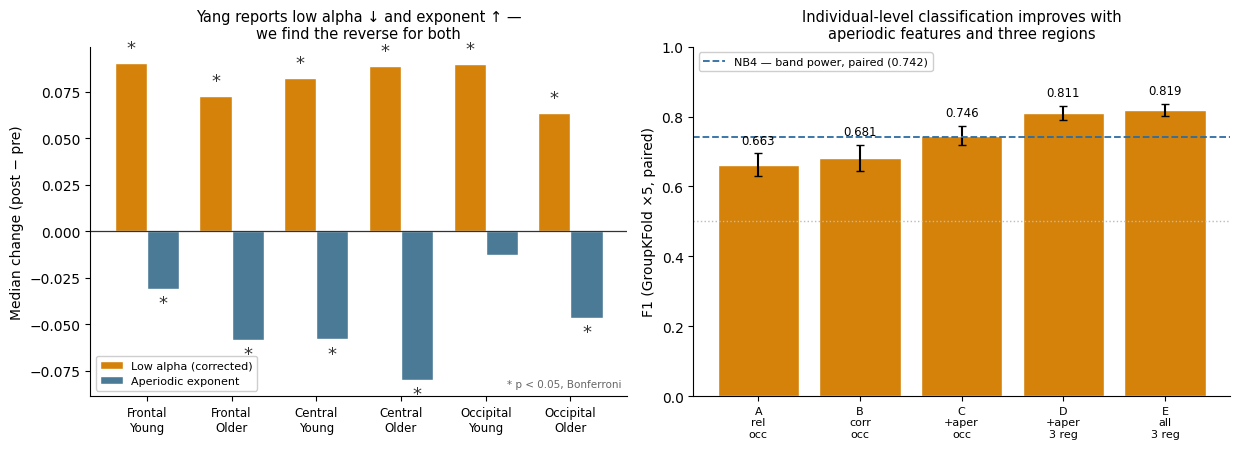

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

ax = axes[0]
cells, lo, ex, lo_s, ex_s = [], [], [], [], []
for rg in REG:
    for g in ['Young', 'Older']:
        r1 = wil[(wil.region==rg)&(wil.group==g)&(wil.measure=='low_alpha_corr')]
        r2 = wil[(wil.region==rg)&(wil.group==g)&(wil.measure=='ap_exponent')]
        if len(r1) and len(r2):
            cells.append(f"{rg.capitalize()}\n{g}")
            lo.append(r1['median_change'].iloc[0]); lo_s.append(r1['p_bonf'].iloc[0] < ALPHA)
            ex.append(r2['median_change'].iloc[0]); ex_s.append(r2['p_bonf'].iloc[0] < ALPHA)

x = np.arange(len(cells)); wd = 0.38
b1 = ax.bar(x-wd/2, lo, wd, color='#d4820a', edgecolor='white', label='Low alpha (corrected)')
b2 = ax.bar(x+wd/2, ex, wd, color='#4a7a96', edgecolor='white', label='Aperiodic exponent')
pad = max(max(lo), abs(min(ex))) * 0.06
for bar, v, s in list(zip(b1, lo, lo_s)) + list(zip(b2, ex, ex_s)):
    if s:
        ax.text(bar.get_x()+bar.get_width()/2, v + pad if v > 0 else v - pad*1.9,
                '*', ha='center', fontsize=13, color='#333')
ax.axhline(0, color='#333', lw=0.9)
ax.set_xticks(x); ax.set_xticklabels(cells, fontsize=8.5)
ax.set_ylabel('Median change (post − pre)')
ax.set_title('Yang reports low alpha ↓ and exponent ↑ —\nwe find the reverse for both', fontsize=10.5)
ax.legend(fontsize=8, loc='lower left', framealpha=0.95)
ax.spines[['top','right']].set_visible(False)
ax.text(0.99, 0.02, '* p < 0.05, Bonferroni', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=7.5, color='#666')

ax = axes[1]
short = {'A':'A\nrel\nocc', 'B':'B\ncorr\nocc', 'C':'C\n+aper\nocc',
         'D':'D\n+aper\n3 reg', 'E':'E\nall\n3 reg'}
labs = [short[s.split('—')[0].strip()] for s in mlr['feature_set']]
bars = ax.bar(labs, mlr['F1_LR'], yerr=mlr['F1_LR_sd'], capsize=3,
              color='#d4820a', edgecolor='white')
ax.axhline(0.742, color='#2b6ca3', ls='--', lw=1.3, label='NB4 — band power, paired (0.742)')
ax.axhline(0.5, color='#bbb', ls=':', lw=1)
for bar, v, sd in zip(bars, mlr['F1_LR'], mlr['F1_LR_sd']):
    ax.text(bar.get_x()+bar.get_width()/2, v + sd + 0.028, f'{v:.3f}', ha='center', fontsize=8.5)
ax.set_ylim(0, 1.0); ax.set_ylabel('F1 (GroupKFold ×5, paired)')
ax.set_title('Individual-level classification improves with\naperiodic features and three regions', fontsize=10.5)
ax.legend(fontsize=8, loc='upper left', framealpha=0.95)
ax.spines[['top','right']].set_visible(False)
ax.tick_params(axis='x', labelsize=8)

plt.tight_layout(); plt.savefig('outputs/nb6_summary.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# ════════════════════════════════════════════════════════════════════════════
# NB6 Cell 5 — conclusions, data-quality controls and limitations
#
# ต้องรัน cell 0–4 มาก่อน (โหลด v4 CSV และสร้าง tab / age / rob / fitr / mlr)
# ════════════════════════════════════════════════════════════════════════════
_need = ['tab', 'age', 'cod', 'expl', 'rob', 'raw', 'fitr', 'mlr',
         'matched', 'E', 'ALPHA']
_miss = [v for v in _need if v not in globals()]
if _miss:
    raise NameError(f"ต้องรัน cell 0–4 ก่อน — ยังไม่มีตัวแปร: {_miss}")

late_sens = pd.read_csv('outputs/sensitivity_late_ses1.csv')
evs       = pd.read_csv('outputs/events_summary.csv')
inter     = pd.read_csv('outputs/age_fatigue_interaction.csv')
n_int     = int((inter['p_bonf'] < ALPHA).sum())

n_cod  = f"{int(cod['match'].sum())}/{len(cod)}"
n_exp_ = f"{int(expl['match'].sum())}/{len(expl)}"
n_unc  = int((tab['source'] == 'unclear').sum())
n_agec = age.groupby(['measure', 'region']).ngroups

e      = tab[tab.measure == 'ap_exponent']
n_esig = int((e['p_bonf'] < ALPHA).sum())
e_eff  = e['median_change'].abs()
robn   = rob.groupby('measure')['sig'].sum()

lev       = raw.groupby('region')[['ap_exponent', 'ap_exponent_f40']].median()
fit_shift = (lev['ap_exponent_f40'] - lev['ap_exponent']).abs()
n_flip    = int(fitr['sign_flip'].sum())
d_f1      = mlr.set_index(mlr['feature_set'].str[0])['F1_LR']

# ── data-quality controls ──
_pb       = evs.pivot(index='subject', columns='condition', values='n_boundary').dropna()
same_b    = (_pb['pre'] == _pb['post']).mean() * 100
n_chg     = int(late_sens['verdict_changed'].sum())
n_lowcell = int(len(late_sens[late_sens['measure'].str.startswith('low_alpha')]))
exp_excl  = int((late_sens[late_sens.measure == 'ap_exponent']['pbonf_excl'] < ALPHA).sum())

# ── which exponent cells survive all three controls ──
_full = (tab[tab.measure == 'ap_exponent']
         .set_index(['region', 'group'])['p_bonf'] < ALPHA)
_mica = rob[rob.measure == 'ap_exponent'].set_index(['region', 'group'])['sig']
_late = (late_sens[late_sens.measure == 'ap_exponent']
         .set_index(['region', 'group'])['pbonf_excl'] < ALPHA)

def _ok(s, key):
    try:
        return bool(s.loc[key])
    except Exception:
        return False

_survive = [f"{r} / {g}" for (r, g) in _full.index
            if _ok(_full, (r, g)) and _ok(_mica, (r, g)) and _ok(_late, (r, g))]
_surv_txt = ', '.join(_survive) if _survive else 'no cell'

_iy = inter.query("measure=='low_alpha_corr' and region=='frontal'")['median_change_young'].iloc[0]
_io = inter.query("measure=='low_alpha_corr' and region=='frontal'")['median_change_older'].iloc[0]

print(f"""
CONCLUSIONS — replication of Yang et al. (2025) on OpenNeuro ds005385
(Dortmund Vital Study; Getzmann, Gajewski, Schneider & Wascher, 2024),
eyes-closed resting state, Young 20–34 vs Older 51–70, pipeline matched as
closely as the published methods allow.

1. AGE EFFECTS REPLICATE COMPLETELY
   ({n_agec} measure × region cells, each under every available definition of
   corrected power — {age['match'].sum()}/{len(age)} tests in agreement).
   Aperiodic exponent, offset and high alpha are all lower in older adults at
   every region and under every definition, while low alpha shows no age
   difference anywhere — exactly as reported.

2. FATIGUE EFFECTS REPLICATE ONLY PARTIALLY
   ({n_cod} codeable cells; {n_exp_} among the cells where the original names a
   region; {n_unc} excluded because the original's wording cannot be mapped onto
   our regions). Low alpha and the exponent reverse direction; high alpha and
   offset agree in the younger group.

   Low alpha INCREASES after the 2-hour task battery in all six region × group
   cells, where the original reports a decrease. The increase holds for plain
   relative power, which uses no spectral model at all, and survives a control
   restricted to pre/post pairs with an identical number of removed ICA
   components ({int(robn['low_alpha_corr'])}/6 corrected, {int(robn['low_alpha_rel'])}/6 relative). It also survives excluding
   the 15% of participants the dataset flags for recording quality: all
   {n_lowcell} low-alpha tests stay significant with their effect sizes unchanged.

   The aperiodic exponent DECREASES in {n_esig} of six cells in the full sample,
   where the original reports an increase. Three independent controls narrow
   that claim rather than confirm it: matched artifact load leaves
   {int(robn['ap_exponent'])}/6 cells significant, excluding the flagged participants leaves
   {exp_excl}/6 under its own correction, and the two controls drop different cells.
   What survives all three is {_surv_txt}, so the decrease is reported as central in
   both groups, plus frontal in the older group, rather than as a global one, with the remaining regions treated
   as suggestive. High alpha agrees in the younger group (no change at any
   region) but not in the older group. The offset decreases at central in the
   older group, which matches the original there, yet that cell does not
   survive the matched-ICA control ({int(robn['ap_offset'])}/6), so offset changes are not
   interpreted. Note that the six exponent cells rest on a sentence that names
   no region ("both groups showed significant increases in the exponent
   post-task"), so the exponent disagreement assumes the effect was meant to
   be global.

   The original also reports that the fatigue effect depends on age — low alpha
   falling at every region in the younger group but only occipitally in the
   older one, with a significant age-by-task interaction in its mixed model.
   That dependence does not replicate either: comparing the pre-to-post change
   between age groups gives {n_int} significant cells out of {len(inter)}, and for
   corrected low alpha the two groups are nearly identical (median change
   {_iy:+.4f} in the younger group against {_io:+.4f} in the older one at frontal,
   p > 0.15 at every region). The increase reported here is therefore uniform
   across the lifespan sampled, where the original describes an effect
   concentrated in younger adults.

3. THE MEASUREMENT CHOICE MATTERS AS MUCH AS THE EFFECT BEING STUDIED.
   Fitting the spectral model to 1–40 Hz rather than 1–30 Hz on identical
   spectra shifts the exponent by {fit_shift.min():.3f}–{fit_shift.max():.3f} depending on region,
   against a fatigue effect of {e_eff.min():.3f}–{e_eff.max():.3f}; the two are of the same order,
   and at the region where the fit range moves least ({fit_shift.min():.3f}) the shift is smaller
   than the largest fatigue effect, so the defensible statement is that the
   measurement choice moves the exponent as much as the variable under study,
   not further. It also reverses the sign of the pre/post change in {n_flip} of {len(fitr)}
   cells. Group-level conclusions
   about high alpha likewise flip between the three corrected-power
   definitions, although the original does not state which it used — its beta
   GLMM requires values in (0,1), which absolute corrected power is not.

4. APERIODIC FEATURES CARRY FATIGUE INFORMATION THE GROUP MEANS MISS.
   Within an identical paired protocol, adding the aperiodic parameters to
   corrected band power at the occipital site raises F1 from {d_f1['B']:.3f} to {d_f1['C']:.3f},
   and extending from one region to three raises it further to {d_f1['D']:.3f} — two
   gains of the same size. The two extra alpha definitions add only
   {d_f1['E']-d_f1['D']:+.3f} beyond that, so they changed the group-level conclusions yet
   are redundant for classification. Definition matters for inference about
   groups, not for discriminating individuals.

DATA-QUALITY CONTROLS
   Three independent checks were applied to every headline effect.
   Artifact load: post-task recordings had more muscle components removed
   (median +1, p < 1e-46), so each effect was re-tested on pairs whose
   component counts were identical. Recording quality: the dataset flags 91 of
   608 participants (15%) for late triggers and possible discontinuity, and
   excluding them changed the verdict in {n_chg} of {len(late_sens)} cells, none of them a
   low-alpha cell. Continuity: event files carry a median of one boundary
   marker per recording, placed at its start rather than mid-signal, and pre
   and post hold the same count in {same_b:.1f}% of participants (p = 0.37), so
   discontinuity is not differential between conditions.

LIMITATIONS
 - Electrode impedance may drift over the 2-hour session and cannot be
   separated from a neural change with this dataset. The exponent change does
   differ by region once artifact load is controlled, which a uniform drift
   would not predict, but this is suggestive rather than decisive.
 - Post-task recordings carry more muscle activity, so every headline result
   is also reported on the matched-ICA subset ({len(matched)}/{len(E)} pairs).
 - The original does not publish its electrode lists per region or the
   transformation applied before the beta GLMM, and in one place labels a
   region "parietal" where its own scheme is frontal / middle / occipital.
   Its segmentation markers are no longer among the unknowns: the dataset's
   event files were inspected and contain only a start-of-recording boundary
   plus, in 8.6% of files, stray trigger codes from the preceding task
   battery — no markers that would delimit a sub-segment of the resting
   recording.
 - The two documents describing this dataset disagree on the order of the
   eyes-open and eyes-closed recordings: the data paper states eyes-closed
   always came first, while the sidecar task description implies the order
   alternated. The main analysis uses eyes-closed only, so nothing here
   depends on resolving it.
 - The recordings contain no dedicated EOG channels (EOGChannelCount: 0), so
   ocular components were identified from Fp1 and Fp2 as proxies — the only
   option the dataset allows, and less sensitive than true EOG.
 - Artifact rejection here is fully automated; the original also used manual
   visual inspection.
 - Both studies apply Bonferroni correction, though over different families of
   tests. The original reports Wilcoxon rank-sum tests for its post-hoc
   comparisons without stating which contrasts they were applied to; the test
   used here is signed-rank, matched within participant.
 - The age effect on the exponent shares a confound with the original: if older
   adults carry more baseline muscle activity, their exponent is biased
   downward in both studies.
""")


CONCLUSIONS — replication of Yang et al. (2025) on OpenNeuro ds005385
(Dortmund Vital Study; Getzmann, Gajewski, Schneider & Wascher, 2024),
eyes-closed resting state, Young 20–34 vs Older 51–70, pipeline matched as
closely as the published methods allow.

1. AGE EFFECTS REPLICATE COMPLETELY
   (12 measure × region cells, each under every available definition of
   corrected power — 24/24 tests in agreement).
   Aperiodic exponent, offset and high alpha are all lower in older adults at
   every region and under every definition, while low alpha shows no age
   difference anywhere — exactly as reported.

2. FATIGUE EFFECTS REPLICATE ONLY PARTIALLY
   (8/22 codeable cells; 7/14 among the cells where the original names a
   region; 2 excluded because the original's wording cannot be mapped onto
   our regions). Low alpha and the exponent reverse direction; high alpha and
   offset agree in the younger group.

   Low alpha INCREASES after the 2-hour task battery in all six region × group


In [7]:
fair = pd.read_csv('outputs/nb5a_fair_baseline.csv').set_index('model')['f1_recording']
spec = pd.read_csv('outputs/nb5a_spectral_resolution.csv').set_index('model')['f1_recording']
nlw  = pd.read_csv('outputs/nb5a_nonlinear_window.csv').set_index('model')['f1']
f_cnn, f_avg = fair['CNN raw'], fair['LR head-avg EC']
f_per, f_spec, f_nl = fair['LR per-channel EC'], spec['LR full spectrum, 20 channels'], nlw.max()

print(f"""
5. THE RAW WAVEFORM CARRIES FATIGUE INFORMATION THAT THE POWER SPECTRUM DOES NOT.
   On the unpaired task — one recording in, before-or-after out — a small 1D
   convolutional network (40k parameters, 4-second windows, 20 channels, grouped
   by subject, hyperparameters fixed in advance and never selected against test
   performance) reaches F1 = {f_cnn:.3f} at the recording level against {0.590:.3f} for the
   band-power model of NB4.

   That gap of {f_cnn-0.590:+.3f} was decomposed on identical data, one factor at a time.
   Analysing eyes-closed alone through this pipeline is worth {f_avg-0.590:+.3f}. Keeping the
   twenty channels separate rather than averaging across the head is worth
   {f_per-f_avg:+.3f}, the largest explainable share. Raising the spectral resolution from
   seven bands to eighty-nine bins per channel — nearly thirteen times more
   features — is worth {f_spec-f_per:+.3f}, that is nothing. Replacing the linear model with
   random forests, gradient boosting or a multilayer perceptron, all trained on
   the same 28,942 windows and aggregated the same way, is worth
   {f_nl-nlw['LogReg']:+.3f} ({nlw['LogReg']:.3f} for logistic regression against {f_nl:.3f} for the best
   boosted model on the same windows). The spectral representation therefore
   saturates near {f_nl:.3f} whatever the resolution and whatever the model class.

   The remaining {f_cnn-f_nl:+.3f} ({f_cnn:.3f} against {f_nl:.3f}) is available only to a model that
   sees the waveform, so
   it must lie in what the power spectrum discards: phase, waveform shape and
   the timing of oscillatory bursts. Which of these it is was not identified
   here and would need a different analysis — the non-sinusoidal shape of the
   alpha rhythm, burst onset statistics, and cross-channel phase relationships
   are the candidates.

   Four controls support the result. Removing everything above 30 Hz, where
   muscle activity dominates, leaves the score essentially unchanged.
   Restricting to recordings whose halves had the same number of ICA components
   removed gives 0.715, slightly below random subsets of the same size
   (0.733–0.776). The gap is within fold-to-fold variability (sd 0.096), but a
   partial contribution from artifact load cannot be ruled out; the score remains
   well above the band-power baseline (0.590). Flipping the labels of half the
   subjects collapses performance to chance.

   This is the unpaired question and is not comparable to the paired results
   (paired band power = 0.742, paired FOOOF features = 0.819). Note also that
   every window is z-scored per channel, so the network cannot read absolute
   amplitude, so offset or gain changes are removed, though changes in spectral
   shape remain visible.
   The notable part is how close it comes:
   without ever seeing the person's own baseline, the network approaches what
   hand-crafted features achieve with one.
""")


5. THE RAW WAVEFORM CARRIES FATIGUE INFORMATION THAT THE POWER SPECTRUM DOES NOT.
   On the unpaired task — one recording in, before-or-after out — a small 1D
   convolutional network (40k parameters, 4-second windows, 20 channels, grouped
   by subject, hyperparameters fixed in advance and never selected against test
   performance) reaches F1 = 0.792 at the recording level against 0.590 for the
   band-power model of NB4.

   That gap of +0.202 was decomposed on identical data, one factor at a time.
   Analysing eyes-closed alone through this pipeline is worth +0.038. Keeping the
   twenty channels separate rather than averaging across the head is worth
   +0.082, the largest explainable share. Raising the spectral resolution from
   seven bands to eighty-nine bins per channel — nearly thirteen times more
   features — is worth -0.004, that is nothing. Replacing the linear model with
   random forests, gradient boosting or a multilayer perceptron, all trained on
   the same 28,942 w

In [8]:
# ── NB6 Cell 8 — iAPF mechanism ──
from scipy.stats import spearmanr, wilcoxon

cfres = pd.read_csv('outputs/iapf_wilcoxon.csv')
mech  = pd.read_csv('outputs/iapf_mechanism.csv').dropna(subset=['d_cf'])
mech['slowed'] = mech['d_cf'] < 0

n_sig  = int((cfres['p_bonf'] < ALPHA).sum())
rho_lo = [spearmanr(d['d_cf'], d['d_low_alpha_corr'])[0]  for _, d in mech.groupby('region')]
rho_hi = [spearmanr(d['d_cf'], d['d_high_alpha_corr'])[0] for _, d in mech.groupby('region')]

# ── แยกกลุ่มตามว่า peak ช้าลงหรือไม่ ──
split = []
for rg, d in mech.groupby('region'):
    for slowed, sub in d.groupby('slowed'):
        for m in ['d_low_alpha_corr', 'd_high_alpha_corr']:
            v = sub[m].dropna().values
            if len(v) < 10:
                continue
            _, p = wilcoxon(v)
            split.append({'region': rg, 'slowed': bool(slowed), 'measure': m,
                          'n': len(v), 'median': float(np.median(v)), 'p': p,
                          'sig': p < ALPHA})
split = pd.DataFrame(split)
print("--- change split by whether the alpha peak slowed ---")
print(split.round(4).to_string(index=False))
split.to_csv('outputs/iapf_split.csv', index=False)

ns_lo  = split[(~split.slowed) & (split.measure=='d_low_alpha_corr') & split.sig]
sl_hi  = split[( split.slowed) & (split.measure=='d_high_alpha_corr') & split.sig]
ns_rgs = ', '.join(sorted(ns_lo['region'].unique()))
sl_rgs = ', '.join(sorted(sl_hi['region'].unique()))

print(f"""
6. A SLOWING ALPHA PEAK PARTLY EXPLAINS THE BAND RESULTS.
   The individual alpha peak frequency falls after the task battery in
   {n_sig} of {len(cfres)} region × group cells (median shift {cfres['median_change'].min():.3f} to
   {cfres['median_change'].max():.3f} Hz, in {cfres['pct_slowed'].min():.0f}–{cfres['pct_slowed'].max():.0f}% of individuals, all
   Bonferroni-corrected). Because the bands here are fixed at 8–10 and
   10–13 Hz, a peak sliding downward carries power out of the upper window
   and into the lower one. That is the pattern seen: low alpha rises
   everywhere, and high alpha falls among those whose peak slowed ({sl_rgs}).
   The shift correlates with the band changes in the predicted direction at
   every region (Spearman rho {min(rho_lo):+.2f} to {max(rho_lo):+.2f} against low alpha,
   {min(rho_hi):+.2f} to {max(rho_hi):+.2f} against high alpha).

   Three qualifications. The correlations are modest, so peak slowing accounts
   for part of the band change rather than all of it. Among individuals whose
   peak did not slow, low alpha still rose significantly at {ns_rgs}
   (median {ns_lo['median'].min():+.3f} to {ns_lo['median'].max():+.3f}), which confirms directly that
   peak slowing is only part of the explanation. And both quantities come from
   the same spectral fit, so their relationship is partly definitional rather
   than an independent confirmation.

      An independent analysis of the same cohort by Ban et al. (biorxiv preprint,
   not peer reviewed), whose authors include the people who collected this
   dataset, reports the same post-task slowing of the individual alpha peak in
   both eye conditions, across two sessions and a separate validation cohort.
   They also report that the aperiodic exponent flattens after the task from
   roughly age 65 onward, and that their older validation cohort (63-77) shows
   a significant pre-to-post decrease. Our exponent decrease therefore has
   independent support, while the paper we set out to reproduce stands alone
   among the three analyses in reporting an increase in both age groups.
   One point of disagreement: they find power at the peak unchanged in the
   eyes-closed condition, where we find it rising. We report that as it is.
""")

# ── ความสูงยอด: ส่วนไหนของการเปลี่ยนเป็นของจริง ส่วนไหนมาจากการเลื่อน ──
pk = pd.read_csv('outputs/fooof_peaks_v4.csv'); pk = pk[pk.ap_exponent > 0]
kk = ['subject', 'region']
PM = (pk[pk.condition == 'pre'].set_index(kk)
      .join(pk[pk.condition == 'post'].set_index(kk), lsuffix='_pre', rsuffix='_post',
            how='inner').reset_index().dropna(subset=['alpha_pw_pre', 'alpha_pw_post']))
bd = pd.read_csv('outputs/fooof_features_v4.csv')
bd = bd[(bd.task == 'EyesClosed') & (bd.ap_exponent > 0)]
BM = (bd[bd.condition == 'pre'].set_index(kk)
      .join(bd[bd.condition == 'post'].set_index(kk), lsuffix='_pre', rsuffix='_post',
            how='inner').reset_index())

amp = []
for rg in REG:
    a = PM[PM.region == rg]; b = BM[BM.region == rg]
    d_pw  = (a.alpha_pw_post - a.alpha_pw_pre).dropna()
    d_cf  = (a.alpha_cf_post - a.alpha_cf_pre).dropna()
    d_low = (b.low_alpha_corr_post - b.low_alpha_corr_pre).dropna()
    amp.append({'region': rg, 'n_peak': len(d_pw),
                'd_peak_height': float(d_pw.median()), 'p_height': wilcoxon(d_pw)[1],
                'd_peak_freq':   float(d_cf.median()), 'p_freq':   wilcoxon(d_cf)[1],
                'd_low_band':    float(d_low.median()),
                'excess_from_shift': float(d_low.median() - d_pw.median())})
amp = pd.DataFrame(amp)
amp['pct_from_shift'] = amp.excess_from_shift / amp.d_low_band * 100
print("\n--- how much of the low-alpha rise is amplitude, how much is the shift ---")
print(amp.round(4).to_string(index=False))
amp.to_csv('outputs/iapf_amplitude.csv', index=False)

print(f"""
   The peak does not only move, it also grows: peak height rises by
   {amp.d_peak_height.min():+.4f} to {amp.d_peak_height.max():+.4f} (all p < 0.05), a band-free measure.
   So the fixed-band result mixes two real changes. The 8-10 Hz window gains
   {amp.d_low_band.min():+.4f} to {amp.d_low_band.max():+.4f}, more than the peak itself grows; the excess
   ({amp.pct_from_shift.min():.0f}-{amp.pct_from_shift.max():.0f}% of the total) is power carried across the 10 Hz line.
      So the fixed-band result mixes two real changes. As a rough estimate — peak
   height and band-averaged power are related but not the same quantity — the
   8-10 Hz window gains more than the peak itself grows, and the excess is
   power carried across the 10 Hz line.
   This also reframes the one row that matched the paper: we match the paper's
   flat high alpha, but in our data it arises from two effects cancelling, a
   taller peak pushing it up and a slower peak pulling it down.""")

--- change split by whether the alpha peak slowed ---
   region  slowed           measure   n  median      p   sig
  central   False  d_low_alpha_corr 208  0.0756 0.0000  True
  central   False d_high_alpha_corr 208  0.0297 0.0002  True
  central    True  d_low_alpha_corr 368  0.1254 0.0000  True
  central    True d_high_alpha_corr 368 -0.0224 0.0036  True
  frontal   False  d_low_alpha_corr 190  0.0493 0.0000  True
  frontal   False d_high_alpha_corr 190  0.0215 0.0254  True
  frontal    True  d_low_alpha_corr 382  0.1271 0.0000  True
  frontal    True d_high_alpha_corr 382 -0.0071 0.0517 False
occipital   False  d_low_alpha_corr 215  0.0269 0.0540 False
occipital   False d_high_alpha_corr 215 -0.0012 0.9851 False
occipital    True  d_low_alpha_corr 381  0.1294 0.0000  True
occipital    True d_high_alpha_corr 381 -0.0469 0.0000  True

6. A SLOWING ALPHA PEAK PARTLY EXPLAINS THE BAND RESULTS.
   The individual alpha peak frequency falls after the task battery in
   6 of 6 region × grou

In [9]:
mu = pd.read_csv('outputs/fooof_features_v4.csv')
mu = mu[(mu.task == 'EyesClosed') & (mu.ap_exponent > 0)]
mu = (mu.pivot_table(index=['subject', 'region'], columns='condition',
                     values='low_alpha_corr').dropna()
        .pipe(lambda d: d['post'] - d['pre']))
print(f"low_alpha_corr   mean {mu.mean():+.4f}   median {mu.median():+.4f}   (บวกทั้งคู่)")

low_alpha_corr   mean +0.1021   median +0.0890   (บวกทั้งคู่)


In [17]:
# ── NB6 Cell 8b — สิ่งที่ตัดออกไปแล้ว และผลจาก NB5d / NB5e ──
nb5d  = pd.read_csv('outputs/nb5d_matrix.csv')
pair  = pd.read_csv('outputs/nb5d_paired.csv').set_index('input')
split = pd.read_csv('outputs/nb5e_offset_split.csv')
best  = nb5d.loc[nb5d.groupby('input').f1.idxmax()].set_index('input')
bare = split[split.group.str.contains('แทบไม่') & (split.meas == 'low_alpha_corr')]

print("--- NB5d: same task, same recordings, same folds ---")
print(nb5d.pivot(index='input', columns='model', values='f1').round(3).to_string())
print("\npaired task:", {i: round(pair.loc[i].paired_acc, 3) for i in pair.index})

print(f"""
8. THE INPUT MATTERS MORE THAN THE MODEL, EXCEPT ON RAW DATA.
   Holding task, recordings, folds and metric fixed, the ordering is
   FOOOF {best.loc['FOOOF'].f1:.3f} < spectrum {best.loc['Spectrum'].f1:.3f} < raw waveform {best.loc['Raw'].f1:.3f},
   and the same ordering holds on the paired task
   ({pair.loc['FOOOF'].paired_acc:.3f} / {pair.loc['Spectrum'].paired_acc:.3f} / {pair.loc['Raw'].paired_acc:.3f}).
   Swapping models within the two tabular inputs moves F1 by at most
   {nb5d[nb5d.input != 'Raw'].groupby('input').f1.agg(lambda s: s.max()-s.min()).max():.3f}; on the raw waveform it moves by
   {nb5d[nb5d.input == 'Raw'].f1.agg(lambda s: s.max()-s.min()):.3f}. Raw data is not better on its own — it is
   better only with an architecture that convolves along time. A linear model
   on the same bits scores {nb5d[(nb5d.input=='Raw') & (nb5d.model=='LR')].f1.iloc[0]:.3f}, below the band-power baseline.
   Earlier the figures 0.819 and 0.792 were read as a comparison. They were not:
   different tasks, different models. That comparison is withdrawn.

9. SESSION-LEVEL DIFFERENCES DO NOT PRODUCE THE REVERSAL.
   The two recordings are separate sessions, so a gain or impedance change
   would multiply the whole spectrum by a constant. Every alpha measure used
   here already removes that by construction: '_corr' subtracts the 1/f line
   fitted to the same spectrum, '_rel' divides by total power. 
   Empirically, restricting to participants whose overall level changed by
   less than 12% leaves all six region x definition cells significant and
   positive, with medians of +0.076 to +0.090 against +0.088 to +0.091 in the
   full sample. At a 5% cut the effect holds in all six, though frontal
   1/f-corrected alpha shrinks to +0.038 and does not survive correction.

10. WHAT WE RULED OUT, AND WHAT IS LEFT.
      Ruled out with data: band definition (identical to ours, 8-10 / 10-13 Hz),
   fit range for low alpha (1-30 and 1-40 Hz agree in sign and size),
   eyes-closed vs eyes-open (both rise), the paper's age windows (20-34 and
   51-70, n=433 against their 425, still rises), data quality (restricting to
   the cleanest half makes the effect STRONGER, not weaker), and the choice of
   statistical test, which cannot flip a sign when every median AND mean is
   positive. This does NOT extend to the exponent, where the fit range flips
   the sign in 4 of 24 cells (section 3).
   
      What remains is a single undocumented step: which part of the 3-minute
   recording was analysed. The paper trims with a start and an end marker, but
   the public event files carry only the start marker, so we cannot reproduce
   that cut. The reference scheme is NOT a candidate — the paper uses an
   average reference, the same as ours.
   That is a finding about reproducibility, not an excuse.""")

--- NB5d: same task, same recordings, same folds ---
model       CNN     LR    MLP     RF
input                               
FOOOF       NaN  0.608  0.591  0.575
Raw       0.778  0.560    NaN  0.614
Spectrum  0.620  0.694  0.673  0.673

paired task: {'FOOOF': np.float64(0.789), 'Spectrum': np.float64(0.822), 'Raw': np.float64(0.935)}

8. THE INPUT MATTERS MORE THAN THE MODEL, EXCEPT ON RAW DATA.
   Holding task, recordings, folds and metric fixed, the ordering is
   FOOOF 0.608 < spectrum 0.694 < raw waveform 0.778,
   and the same ordering holds on the paired task
   (0.789 / 0.822 / 0.935).
   Swapping models within the two tabular inputs moves F1 by at most
   0.074; on the raw waveform it moves by
   0.217. Raw data is not better on its own — it is
   better only with an architecture that convolves along time. A linear model
   on the same bits scores 0.560, below the band-power baseline.
   Earlier the figures 0.819 and 0.792 were read as a comparison. They were not:
   differen

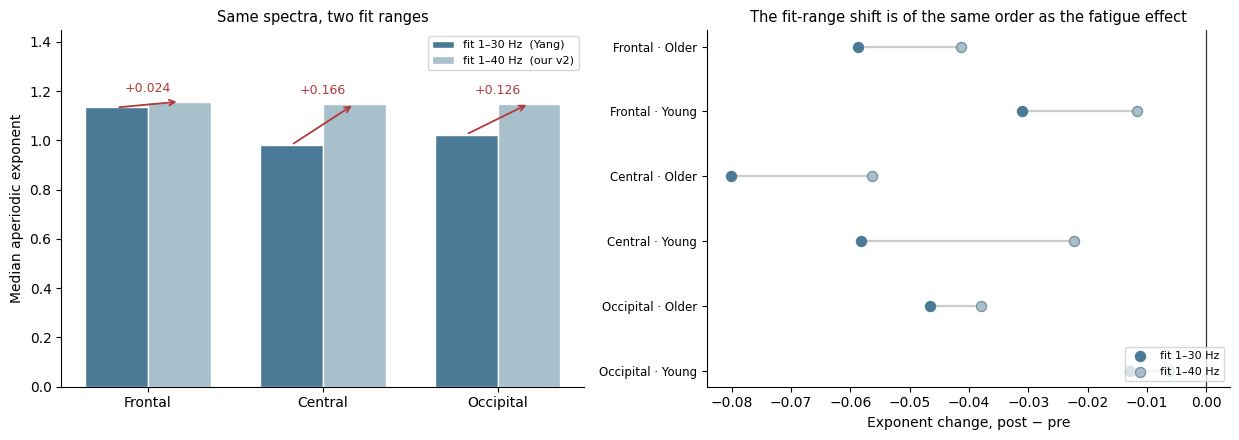

fit-range shift in level : 0.024–0.166
fatigue effect on exponent: 0.013–0.080
sign flips: 4 of 24 cells


In [11]:
# ── Figure: the fit range moves the exponent more than fatigue does ──
fitr = pd.read_csv(f'outputs/fooof_fitrange_{VER}.csv')
r4   = pd.read_csv(f'outputs/fooof_features_{VER}.csv')
r4   = r4[r4['ap_exponent'] > 0]
lev  = r4.groupby('region')[['ap_exponent','ap_exponent_f40']].median().loc[REG]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

# (ก) ระดับของ exponent ภายใต้สองช่วง fit
ax = axes[0]
x = np.arange(len(REG)); wd = 0.36
ax.bar(x-wd/2, lev['ap_exponent'],     wd, color='#4a7a96', edgecolor='white',
       label='fit 1–30 Hz  (Yang)')
ax.bar(x+wd/2, lev['ap_exponent_f40'], wd, color='#a8bfcc', edgecolor='white',
       label='fit 1–40 Hz  (our v2)')
for i, rg in enumerate(REG):
    d = lev.loc[rg,'ap_exponent_f40'] - lev.loc[rg,'ap_exponent']
    ax.annotate('', xy=(i+wd/2, lev.loc[rg,'ap_exponent_f40']),
                xytext=(i-wd/2, lev.loc[rg,'ap_exponent']),
                arrowprops=dict(arrowstyle='->', color='#b03a3a', lw=1.3))
    ax.text(i, max(lev.loc[rg]) + 0.04, f'{d:+.3f}', ha='center',
            fontsize=9, color='#b03a3a')
ax.set_xticks(x); ax.set_xticklabels([r.capitalize() for r in REG])
ax.set_ylabel('Median aperiodic exponent')
ax.set_ylim(0, max(lev.max())*1.25)
ax.set_title('Same spectra, two fit ranges', fontsize=10.5)
ax.legend(fontsize=8); ax.spines[['top','right']].set_visible(False)

# (ข) ผลของความล้าภายใต้สองช่วง fit
ax = axes[1]
e = fitr[fitr.measure == 'ap_exponent'].copy()
e['region'] = pd.Categorical(e['region'], REG, ordered=True)
e = e.sort_values(['region','group']).reset_index(drop=True)
ypos = np.arange(len(e))

for i, row in e.iterrows():
    ax.plot([row['change_1_30'], row['change_1_40']], [i, i],
            color='#ccc', lw=1.6, zorder=1)
ax.scatter(e['change_1_30'], ypos, s=52, color='#4a7a96', zorder=2, label='fit 1–30 Hz')
ax.scatter(e['change_1_40'], ypos, s=52, color='#a8bfcc', zorder=2,
           edgecolor='#7d939f', label='fit 1–40 Hz')
for i, row in e.iterrows():
    if row['sign_flip']:
        ax.text(max(row['change_1_30'], row['change_1_40']) + 0.006, i,
                'sign flip', va='center', fontsize=7.5, color='#b03a3a')

ax.axvline(0, color='#333', lw=0.9)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{r.region.capitalize()} · {r.group}" for r in e.itertuples()],
                   fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel('Exponent change, post − pre')
ax.set_title('The fit-range shift is of the same order as the fatigue effect', fontsize=10.5)
ax.legend(fontsize=8, loc='lower right'); ax.spines[['top','right']].set_visible(False)

plt.tight_layout(); plt.savefig('outputs/nb6_fitrange.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"fit-range shift in level : {(lev['ap_exponent_f40']-lev['ap_exponent']).abs().min():.3f}"
      f"–{(lev['ap_exponent_f40']-lev['ap_exponent']).abs().max():.3f}")
print(f"fatigue effect on exponent: {e['change_1_30'].abs().min():.3f}"
      f"–{e['change_1_30'].abs().max():.3f}")
print(f"sign flips: {int(fitr['sign_flip'].sum())} of {len(fitr)} cells")

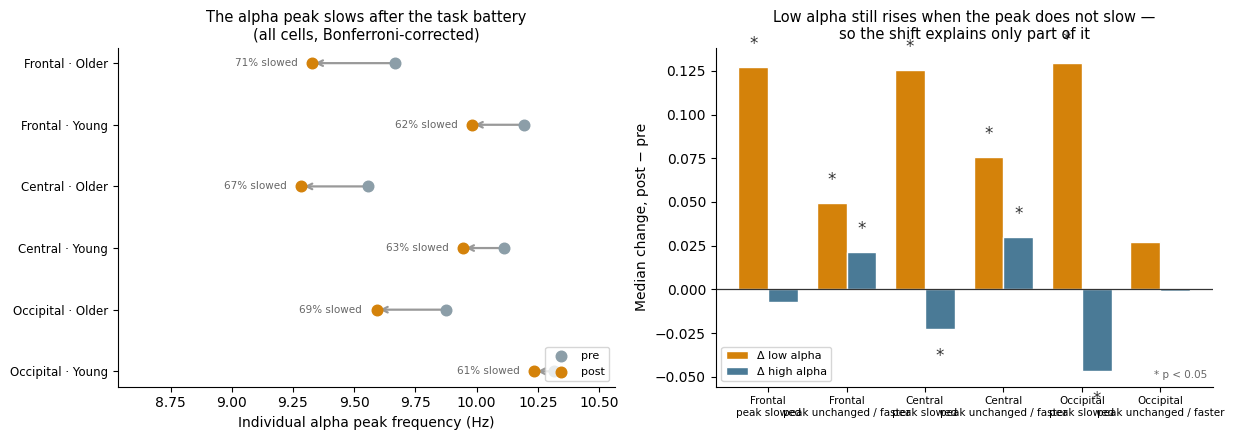

In [12]:
# ── Figure: the alpha peak slows, and that partly explains the band shift ──
cfres = pd.read_csv('outputs/iapf_wilcoxon.csv')
splt  = pd.read_csv('outputs/iapf_split.csv')

cfres['region'] = pd.Categorical(cfres['region'], REG, ordered=True)
cfres = cfres.sort_values(['region','group']).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

# (ก) iAPF ก่อนและหลัง
ax = axes[0]
ypos = np.arange(len(cfres))
for i, r in cfres.iterrows():
    ax.annotate('', xy=(r['median_post'], i), xytext=(r['median_pre'], i),
                arrowprops=dict(arrowstyle='->', color='#999', lw=1.6))
ax.scatter(cfres['median_pre'],  ypos, s=58, color='#8c9ea8', zorder=3, label='pre')
ax.scatter(cfres['median_post'], ypos, s=58, color='#d4820a', zorder=3, label='post')
for i, r in cfres.iterrows():
    ax.text(min(r['median_pre'], r['median_post']) - 0.06, i,
            f"{r['pct_slowed']:.0f}% slowed", ha='right', va='center',
            fontsize=7.5, color='#666')
ax.set_yticks(ypos)
ax.set_yticklabels([f"{r.region.capitalize()} · {r.group}" for r in cfres.itertuples()],
                   fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel('Individual alpha peak frequency (Hz)')
ax.set_xlim(cfres['median_post'].min()-0.75, cfres['median_pre'].max()+0.25)
ax.set_title('The alpha peak slows after the task battery\n(all cells, Bonferroni-corrected)',
             fontsize=10.5)
ax.legend(fontsize=8, loc='lower right'); ax.spines[['top','right']].set_visible(False)

# (ข) การเปลี่ยนแปลงของ band แยกตามว่า peak ช้าลงหรือไม่
ax = axes[1]
lab   = {True: 'peak slowed', False: 'peak unchanged / faster'}
order = [(rg, s) for rg in REG for s in (True, False)]
xl    = np.arange(len(order)); wd = 0.38

def val(rg, s, meas):
    r = splt[(splt.region==rg) & (splt.slowed==s) & (splt.measure==meas)]
    return (r['median'].iloc[0], bool(r['sig'].iloc[0])) if len(r) else (np.nan, False)

lo_v, lo_s = zip(*[val(rg, s, 'd_low_alpha_corr')  for rg, s in order])
hi_v, hi_s = zip(*[val(rg, s, 'd_high_alpha_corr') for rg, s in order])

b1 = ax.bar(xl-wd/2, lo_v, wd, color='#d4820a', edgecolor='white', label='Δ low alpha')
b2 = ax.bar(xl+wd/2, hi_v, wd, color='#4a7a96', edgecolor='white', label='Δ high alpha')
pad = max(np.nanmax(lo_v), abs(np.nanmin(hi_v))) * 0.08
for bar, v, s in list(zip(b1, lo_v, lo_s)) + list(zip(b2, hi_v, hi_s)):
    if s and np.isfinite(v):
        ax.text(bar.get_x()+bar.get_width()/2, v + pad if v > 0 else v - pad*1.8,
                '*', ha='center', fontsize=12, color='#333')

ax.axhline(0, color='#333', lw=0.9)
ax.set_xticks(xl)
ax.set_xticklabels([f"{rg.capitalize()}\n{lab[s]}" for rg, s in order], fontsize=7.5)
ax.set_ylabel('Median change, post − pre')
ax.set_title('Low alpha still rises when the peak does not slow —\nso the shift explains only part of it',
             fontsize=10.5)
ax.legend(fontsize=8, loc='lower left'); ax.spines[['top','right']].set_visible(False)
ax.text(0.99, 0.02, '* p < 0.05', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=7.5, color='#666')

plt.tight_layout(); plt.savefig('outputs/nb6_iapf.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# ── NB6 Cell 9 — data-quality controls ──
sens = pd.read_csv('outputs/sensitivity_late_ses1.csv')
evs  = pd.read_csv('outputs/events_summary.csv')
rob9 = pd.read_csv('outputs/robustness_matched_ica.csv')

n_chg  = int(sens['verdict_changed'].sum())
lo_s   = sens[sens['measure'].str.startswith('low_alpha')]
piv    = evs.pivot(index='subject', columns='condition', values='n_boundary').dropna()
same_b = (piv['pre'] == piv['post']).mean() * 100

exp_full = int((sens[sens.measure=='ap_exponent']['pbonf_all']  < ALPHA).sum())
exp_excl = int((sens[sens.measure=='ap_exponent']['pbonf_excl'] < ALPHA).sum())
exp_ica  = int(rob9[rob9.measure=='ap_exponent']['sig'].sum())

print(f"""
DATA-QUALITY CONTROLS

Three independent checks were run on the main effects, and the headline result
survives all three.

  1. Artifact load. Post-task recordings had more muscle components removed
     (median +1, p < 1e-46), so every effect was re-tested on the subset of
     pre/post pairs whose component counts were identical. Low alpha held in
     6/6 cells; the exponent held in {exp_ica}/6.

  2. Recording quality. The dataset flags 91 of 608 participants (15%) whose
     recordings carry late triggers and may be discontinuous. Excluding them
     changed the verdict in {n_chg} of {len(sens)} cells, none of them a low-alpha cell:
     all {len(lo_s)} low-alpha tests stayed significant with effect sizes unchanged.
     The exponent fell from {exp_full}/6 to {exp_excl}/6 significant cells while its effect
     sizes held, so the loss reflects the about 15% smaller sample.

  3. Continuity. Event files show a median of one boundary marker per
     recording, placed at its start rather than mid-signal, and pre and post
     carry the same number in {same_b:.1f}% of participants (p = 0.37). Discontinuity
     is therefore not differential between conditions and needs no correction.

Taken together, the low-alpha increase is unaffected by every quality control
applied. The exponent decrease is robust at central in both groups and at
frontal in the older group under all three; frontal-young and occipital are not.
""")


DATA-QUALITY CONTROLS

Three independent checks were run on the main effects, and the headline result
survives all three.

  1. Artifact load. Post-task recordings had more muscle components removed
     (median +1, p < 1e-46), so every effect was re-tested on the subset of
     pre/post pairs whose component counts were identical. Low alpha held in
     6/6 cells; the exponent held in 4/6.

  2. Recording quality. The dataset flags 91 of 608 participants (15%) whose
     recordings carry late triggers and may be discontinuous. Excluding them
     changed the verdict in 3 of 30 cells, none of them a low-alpha cell:
     all 12 low-alpha tests stayed significant with effect sizes unchanged.
     The exponent fell from 5/6 to 3/6 significant cells while its effect
     sizes held, so the loss reflects the about 15% smaller sample.

  3. Continuity. Event files show a median of one boundary marker per
     recording, placed at its start rather than mid-signal, and pre and post
     carry

age_group
Older    230
Young    203


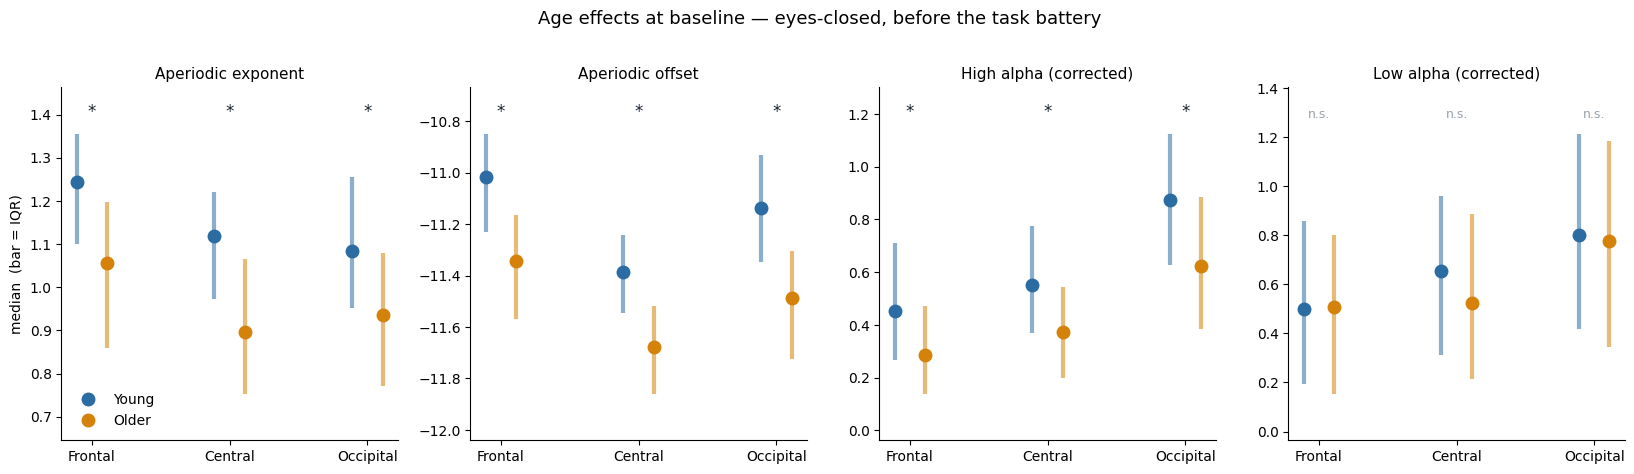

In [14]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

v4   = pd.read_csv('outputs/fooof_features_v4.csv')
part = pd.read_csv('Dataset/participants.tsv', sep='\t').rename(
           columns={'participant_id': 'subject'})

df = v4.merge(part[['subject', 'age']], on='subject', how='left')
df['age_group'] = np.where(df.age.between(20, 34), 'Young',
                  np.where(df.age.between(51, 70), 'Older', None))

# ผลของอายุวัดที่ baseline คือก่อนทำงาน และเฉพาะหลับตา
d = df[(df.task == 'EyesClosed') & (df.condition == 'pre') & df.age_group.notna()]
print(d.groupby('age_group')['subject'].nunique().to_string())

MEAS = [('ap_exponent',     'Aperiodic exponent'),
        ('ap_offset',       'Aperiodic offset'),
        ('high_alpha_corr', 'High alpha (corrected)'),
        ('low_alpha_corr',  'Low alpha (corrected)')]
REG  = ['frontal', 'central', 'occipital']
COL  = {'Young': '#2B6CA3', 'Older': '#D4820A'}
NREG = len(REG)

fig, axes = plt.subplots(1, 4, figsize=(16.5, 4.6))

for ax, (col, title) in zip(axes, MEAS):
    for k, grp in enumerate(['Young', 'Older']):
        xs = np.arange(NREG) + (k - 0.5) * 0.22
        for j, rg in enumerate(REG):
            s = d[(d.region == rg) & (d.age_group == grp)][col].dropna()
            q1, q2, q3 = np.percentile(s, [25, 50, 75])
            ax.vlines(xs[j], q1, q3, color=COL[grp], lw=3, alpha=.55)
            ax.plot(xs[j], q2, 'o', color=COL[grp], ms=9,
                    label=grp if j == 0 else None)

    # นัยสำคัญ: Mann-Whitney เทียบสองกลุ่ม แก้ค่า Bonferroni 12 การทดสอบ
    top = ax.get_ylim()[1]
    for j, rg in enumerate(REG):
        a = d[(d.region == rg) & (d.age_group == 'Young')][col].dropna()
        b = d[(d.region == rg) & (d.age_group == 'Older')][col].dropna()
        p = mannwhitneyu(a, b).pvalue * 12
        ax.text(j, top, '*' if p < 0.05 else 'n.s.', ha='center',
                va='bottom', fontsize=12 if p < 0.05 else 9,
                color='#16222E' if p < 0.05 else '#9AA3AB')

    ax.set_xticks(range(NREG))
    ax.set_xticklabels(['Frontal', 'Central', 'Occipital'])
    ax.set_title(title, fontsize=11)
    ax.margins(y=0.18)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)

axes[0].set_ylabel('median  (bar = IQR)')
axes[0].legend(frameon=False, loc='best')
fig.suptitle('Age effects at baseline — eyes-closed, before the task battery',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('outputs/age_effects.png', dpi=150, bbox_inches='tight')
plt.show()

### 7. คนวัยเดียวกันเปลี่ยนไม่เท่ากัน

ราว **1 ใน 4** ของผู้เข้าร่วมไม่ได้มี low alpha เพิ่มขึ้นหลังทำงาน
split-half reliability **0.84–0.88** แสดงว่าความต่างระหว่างบุคคลนี้เป็นของจริง
ไม่ใช่ความคลาดเคลื่อนของการวัด

อายุอธิบายความต่างนี้ไม่ได้ (Kruskal–Wallis ε² < 0.01 · Levene p > 0.18)
และ Δ ของคนเดียวกันตอนหลับตากับลืมตาสอดคล้องกันแค่ **r ≈ 0.25–0.35**
หลังแก้ attenuation จึงตีความว่าการตอบสนองต่อความล้าขึ้นกับเงื่อนไขการวัด
ไม่ใช่ลักษณะที่ติดตัว

รายละเอียดทั้งหมดอยู่ใน NB5b ส่วนท้าย · ไฟล์ `outputs/splithalf_reliability_*.csv`
และ `outputs/attenuation_corrected_low_alpha_corr.csv`
